# Python 與 Julia 模型比較報告

此 Notebook 使用 Julia 語言，透過 PyCall 套件呼叫 Python 程式碼，比較三步驟模型和四步驟模型的動力學行為。

## 1. 環境設定

首先，我們需要安裝並載入必要的 Julia 套件。如果尚未安裝，請取消註解並執行以下指令。

In [3]:
# 使用 Julia 的套件管理器 Pkg
import Pkg

# 安裝必要的套件 (如果尚未安裝)
# Pkg.add("Plots")
# Pkg.add("Measures")
# Pkg.add("Printf")
# Pkg.add("Markdown")
# Pkg.add("DataFrames")
# Pkg.add("PyCall")
# Pkg.add("IJulia") # Jupyter Notebook 核心

# 載入套件
using Plots
using Measures
using Printf
using Markdown
using DataFrames
using PyCall

# 設定預設字體以避免 GKS 錯誤
default(fontfamily="Helvetica")

# 確保 Python 環境中有 numpy 套件
try
    global np = pyimport("numpy")
catch e
    println("無法導入 numpy。請確保您的 Python 環境已配置 PyCall 且安裝了 numpy。")
    println("嘗試使用 Conda 安裝 numpy...")
    try
        pyimport_conda("numpy", "numpy")
        global np = pyimport("numpy")
        println("成功安裝並導入 numpy。")
    catch e2
        println("使用 Conda 安裝 numpy 失敗: $e2")
        rethrow(e)
    end
end

# 導入 Python 模組 (假設路徑正確)
try 
    push!(PyVector(pyimport("sys")["path"]), "SI_for_Publications/2023_Nature_Communications_Optimum_Km")
    global py_enzyme_kinetics = pyimport("enzyme_kinetics")
catch e
    println("錯誤：無法導入 Python 模組 'enzyme_kinetics'。")
    println("請確認路徑 'SI_for_Publications/2023_Nature_Communications_Optimum_Km' 是否正確，且該目錄下存在 'enzyme_kinetics.py' 檔案。")
    rethrow(e)
end

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
    Updating `~/.julia/environments/v1.11/Project.toml`
  [de0858da] + Printf v1.11.0
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
    Updating `~/.julia/environments/v1.11/Project.toml`
  [d6f4376e] + Markdown v1.11.0
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...

PyObject <module 'enzyme_kinetics' from '/Users/guojunhua/Documents/SynBio/SI_for_Publications/2023_Nature_Communications_Optimum_Km/enzyme_kinetics.py'>

## 2. 載入與定義函數

載入 `thermo_kinetics_modified.jl` 中的核心定義，並定義 Notebook 中需要的比較與繪圖函數。

In [5]:
# 載入核心動力學計算和火山圖函數
include("thermo_kinetics_modified.jl")

# --- 從 model_comparison_pycall.jl 複製必要的函數 --- 

# 使用 PyCall 直接呼叫 Python 程式碼計算邏輯
function python_model_calculation(dG1::Float64, dGT::Float64, S::Float64)
    py_dG1 = np.array([[dG1]])
    py_dGT = np.array([[dGT]])
    result = py_enzyme_kinetics.get_Km_v(py_dG1, py_dGT, S, k10=1.0, k20=1.0, a1=0.5, a2=0.5)
    
    Km_py = result[1]  # Julia 索引從 1 開始
    v_py = result[2]
    
    Km = 0.0
    v = 0.0
    # 處理 PyObject 到 Julia 類型的轉換
    try
        if isa(Km_py, Array) && length(size(Km_py)) == 2
            Km = Km_py[1, 1] * 1e3
        elseif isa(Km_py, Array) && length(size(Km_py)) == 1
            Km = Km_py[1] * 1e3
        elseif isa(Km_py, Number)
            Km = Km_py * 1e3
        else
             Km = PyFloat(Km_py) * 1e3 # 嘗試轉換為 Float
        end
    catch e
        println("處理 Km_py 時出錯: $e. Km_py type=$(typeof(Km_py))")
        Km = NaN
    end
    
    try
        if isa(v_py, Array) && length(size(v_py)) == 2
            v = v_py[1, 1] * 1e3
        elseif isa(v_py, Array) && length(size(v_py)) == 1
            v = v_py[1] * 1e3
        elseif isa(v_py, Number)
            v = v_py * 1e3
        else
            v = PyFloat(v_py) * 1e3 # 嘗試轉換為 Float
        end
    catch e
        println("處理 v_py 時出錯: $e. v_py type=$(typeof(v_py))")
        v = NaN
    end
    
    return Km, v
end

# 定義比較函數
function compare_models(ΔGT::Float64, ΔG1::Float64, S_values::Vector{Float64})
    println("\n開始比較三步驟與四步驟模型...") # 在 Notebook 中提供進度信息
    println("參數設定: ΔGT = $ΔGT kJ/mol, ΔG1 = $ΔG1 kJ/mol")
    
    results_df = DataFrame(
        S_mM = Float64[], S_uM = Float64[],
        Python_Km = Float64[], Julia_Three_Step_Km = Float64[], Julia_Four_Step_Km = Float64[],
        Python_v = Float64[], Julia_Three_Step_v = Float64[], Julia_Four_Step_v = Float64[],
        Python_log10v = Float64[], Julia_Three_Step_log10v = Float64[], Julia_Four_Step_log10v = Float64[]
    )
    
    for S in S_values
        # 1. Python 模型計算
        py_Km, py_v = python_model_calculation(ΔG1, ΔGT, S)
        
        # 2. Julia 三步驟模型計算
        julia_three_params = ThermoKineticsParams(ΔGT=ΔGT, ΔG1=ΔG1, model_type="three_step")
        julia_three_results = calculate_kinetics(julia_three_params)
        julia_three_Km = julia_three_results.Km
        S_uM = S * 1000.0
        RT = 8.314 / 1000 * 300.0
        g1 = exp(ΔG1/RT)
        gT = exp(ΔGT/RT)
        # 使用與 python_model_calculation 一致的速率公式
        julia_three_v = 1.0 * g1^0.5 / gT^0.5 * S_uM * julia_three_params.ET * 1000.0 / (S_uM + julia_three_Km)
        
        # 3. Julia 四步驟模型計算
        julia_four_params = ThermoKineticsParams(ΔGT=ΔGT, ΔG1=ΔG1, model_type="four_step")
        julia_four_results = calculate_kinetics(julia_four_params)
        julia_four_Km = julia_four_results.Km
        julia_four_v = julia_four_results.k_forward * julia_four_params.ET * 1000.0 * S_uM / (S_uM + julia_four_Km)
        
        # 處理可能的零或負速率值以避免 log10 錯誤
        safe_log10(x) = (isa(x, Number) && x > 0) ? log10(x) : NaN
        
        push!(results_df, (
            S, S_uM,
            py_Km, julia_three_Km, julia_four_Km,
            py_v, julia_three_v, julia_four_v,
            safe_log10(py_v), safe_log10(julia_three_v), safe_log10(julia_four_v)
        ))
    end
    println("模型比較計算完成。")
    return results_df
end

# --- Notebook 版本的繪圖函數 --- 

# 繪製比較圖表 (返回圖表物件)
function plot_comparison_notebook(results_df::DataFrame)
    p1 = plot(results_df.S_mM, results_df.Python_Km, label="Python Three-Step", marker=:circle, linewidth=2,
              xlabel="Substrate Concentration [mM]", ylabel="Km [μM]",
              title="Michaelis Constant (Km) Comparison", legend=:topleft,
              xscale=:log10, yscale=:log10)
    plot!(p1, results_df.S_mM, results_df.Julia_Three_Step_Km, label="Julia Three-Step", marker=:square, linewidth=2)
    plot!(p1, results_df.S_mM, results_df.Julia_Four_Step_Km, label="Julia Four-Step", marker=:diamond, linewidth=2)
    
    p2 = plot(results_df.S_mM, results_df.Python_v, label="Python Three-Step", marker=:circle, linewidth=2,
              xlabel="Substrate Concentration [mM]", ylabel="Reaction Rate [μM/s]",
              title="Reaction Rate Comparison", legend=:bottomright, xscale=:log10)
    plot!(p2, results_df.S_mM, results_df.Julia_Three_Step_v, label="Julia Three-Step", marker=:square, linewidth=2)
    plot!(p2, results_df.S_mM, results_df.Julia_Four_Step_v, label="Julia Four-Step", marker=:diamond, linewidth=2)
    
    p3 = plot(results_df.S_mM, results_df.Python_log10v, label="Python Three-Step", marker=:circle, linewidth=2,
              xlabel="Substrate Concentration [mM]", ylabel="log10(Reaction Rate) [log10(μM/s)]",
              title="log10(Reaction Rate) Comparison", legend=:bottomright, xscale=:log10)
    plot!(p3, results_df.S_mM, results_df.Julia_Three_Step_log10v, label="Julia Three-Step", marker=:square, linewidth=2)
    plot!(p3, results_df.S_mM, results_df.Julia_Four_Step_log10v, label="Julia Four-Step", marker=:diamond, linewidth=2)
    
    p_combined = plot(p1, p2, p3, layout=(3,1), size=(800, 900), margin=10mm)
    return p_combined
end

# 繪製火山圖比較 (返回圖表物件)
function plot_volcano_comparison_notebook(ΔGT::Float64, ΔG1::Float64)
    # Volcano plot needs fixed 4 S values
    fixed_S_values = [0.1, 1.0, 10.0, 100.0]  # mM
    
    # Use Julia three-step model to plot volcano plot
    params_three = ThermoKineticsParams(
        ΔGT = ΔGT, ΔG1 = ΔG1,
        model_type = "three_step"
    )
    # plot_activity_volcano is defined in thermo_kinetics_modified.jl (included)
    volcano_three = plot_activity_volcano(params_three, fixed_S_values)
    
    # Use Julia four-step model to plot volcano plot
    params_four = ThermoKineticsParams(
        ΔGT = ΔGT, ΔG1 = ΔG1,
        model_type = "four_step"
    )
    volcano_four = plot_activity_volcano(params_four, fixed_S_values)
    
    return volcano_three, volcano_four
end

plot_volcano_comparison_notebook (generic function with 1 method)

## 3. 模型比較執行

設定模型參數並執行比較計算。

In [7]:
# 設定參數
ΔGT_val = -40.0  # kJ/mol
ΔG1_val = -15.0  # kJ/mol
S_val_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]  # mM

# 比較模型
results_data = compare_models(ΔGT_val, ΔG1_val, S_val_range)

# 繪製比較圖
comparison_plot = plot_comparison_notebook(results_data)

# 繪製火山圖
volcano_plot_three, volcano_plot_four = plot_volcano_comparison_notebook(ΔGT_val, ΔG1_val)


開始比較三步驟與四步驟模型...
參數設定: ΔGT = -40.0 kJ/mol, ΔG1 = -15.0 kJ/mol
模型比較計算完成。


(Plot{Plots.GRBackend() n=8}, Plot{Plots.GRBackend() n=8})

## 4. 結果展示

### 4.1 參數設定

In [9]:
md"""
- ΔGT (總反應自由能變化): $(ΔGT_val) kJ/mol
- ΔG1 (酶-底物複合物自由能變化): $(ΔG1_val) kJ/mol
- Temperature (T): 300 K
- Gas Constant (R): 8.314 J/(mol·K)
- α1 (BEP 關係敏感係數 1): 0.5
- α2 (BEP 關係敏感係數 2): 0.5
- k10 (基準速率常數 1): 1.0
- k20 (基準速率常數 2): 1.0
- ET (總酶濃度): 0.01 mM
"""

  * ΔGT (總反應自由能變化): -40.0 kJ/mol
  * ΔG1 (酶-底物複合物自由能變化): -15.0 kJ/mol
  * Temperature (T): 300 K
  * Gas Constant (R): 8.314 J/(mol·K)
  * α1 (BEP 關係敏感係數 1): 0.5
  * α2 (BEP 關係敏感係數 2): 0.5
  * k10 (基準速率常數 1): 1.0
  * k20 (基準速率常數 2): 1.0
  * ET (總酶濃度): 0.01 mM


### 4.2 模型比較

此報告比較三種模型計算結果：
1.  Python 實現的三步驟模型 (透過 PyCall 在 Julia 中重現)
2.  Julia 實現的三步驟模型
3.  Julia 實現的四步驟模型

### 4.3 計算結果表格

In [12]:
# 顯示計算結果的 DataFrame
results_data

Row,S_mM,S_uM,Python_Km,Julia_Three_Step_Km,Julia_Four_Step_Km,Python_v,Julia_Three_Step_v,Julia_Four_Step_v,Python_log10v,Julia_Three_Step_log10v,Julia_Four_Step_log10v
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.001,1.0,7425.95,7425.95,20359.4,0.202168,0.202168,2.63441e-7,-0.694288,-0.694288,-6.57932
2,0.01,10.0,7425.95,7425.95,20359.4,2.01923,2.01923,2.63325e-6,0.305186,0.305186,-5.57951
3,0.1,100.0,7425.95,7425.95,20359.4,19.9508,19.9508,2.62166e-5,1.29996,1.29996,-4.58142
4,1.0,1000.0,7425.95,7425.95,20359.4,178.198,178.198,0.00025112,2.2509,2.2509,-3.60012
5,10.0,10000.0,7425.95,7425.95,20359.4,861.639,861.639,0.00176676,2.93533,2.93533,-2.75282
6,100.0,100000.0,7425.95,7425.95,20359.4,1397.7,1397.7,0.00445646,3.14541,3.14541,-2.35101


### 4.4 圖像比較

#### 4.4.1 模型參數比較圖 (Km, v, log10(v))

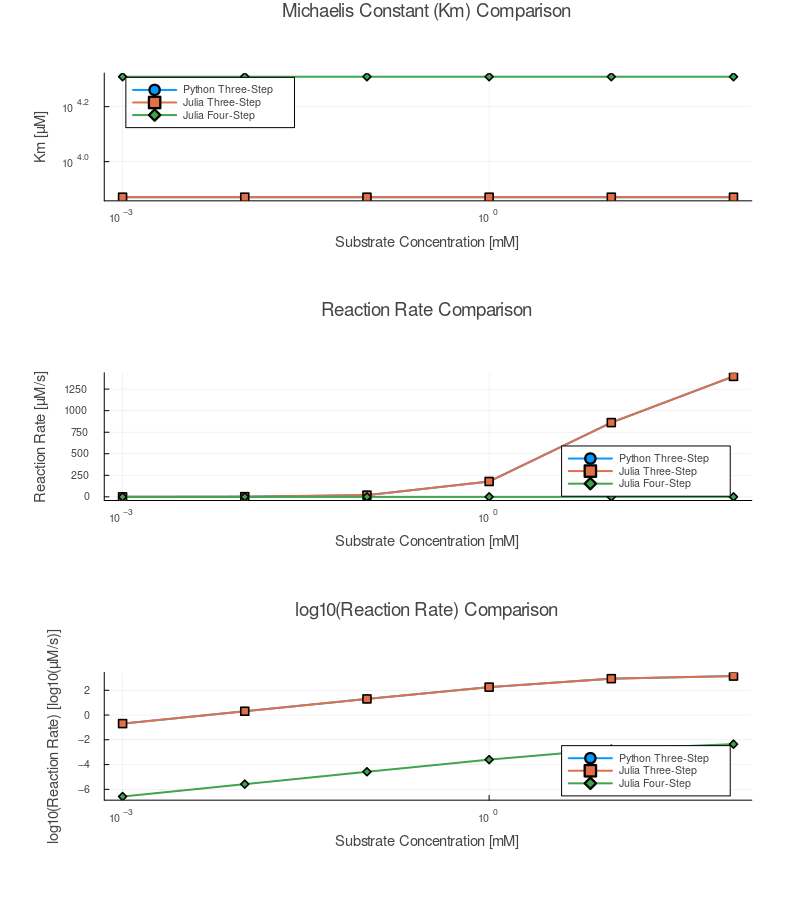

In [14]:
# 顯示比較圖
comparison_plot

#### 4.4.2 三步驟模型火山圖

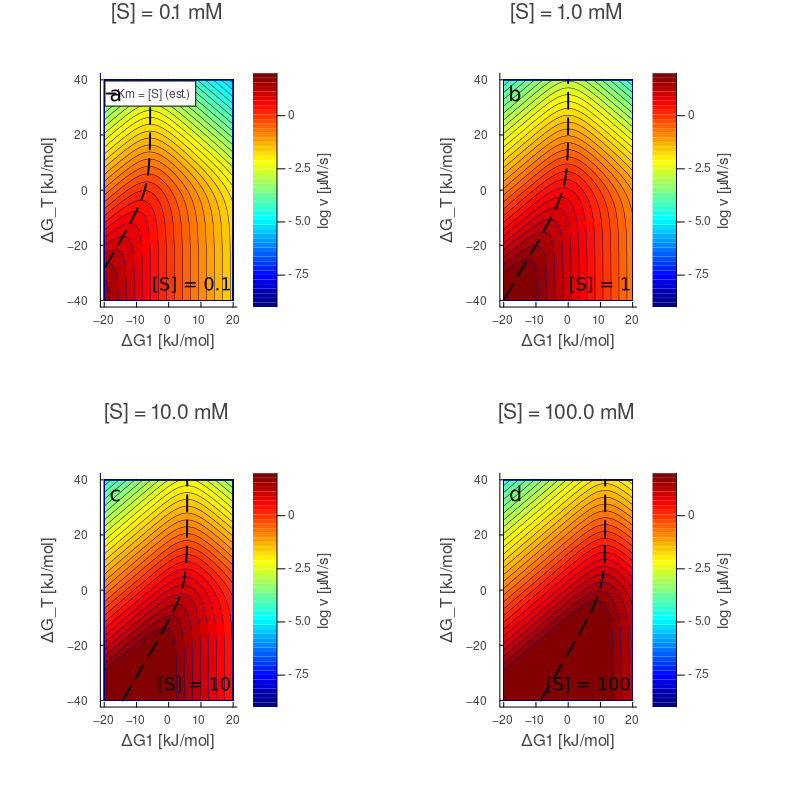

In [16]:
# 顯示三步驟火山圖
volcano_plot_three

#### 4.4.3 四步驟模型火山圖

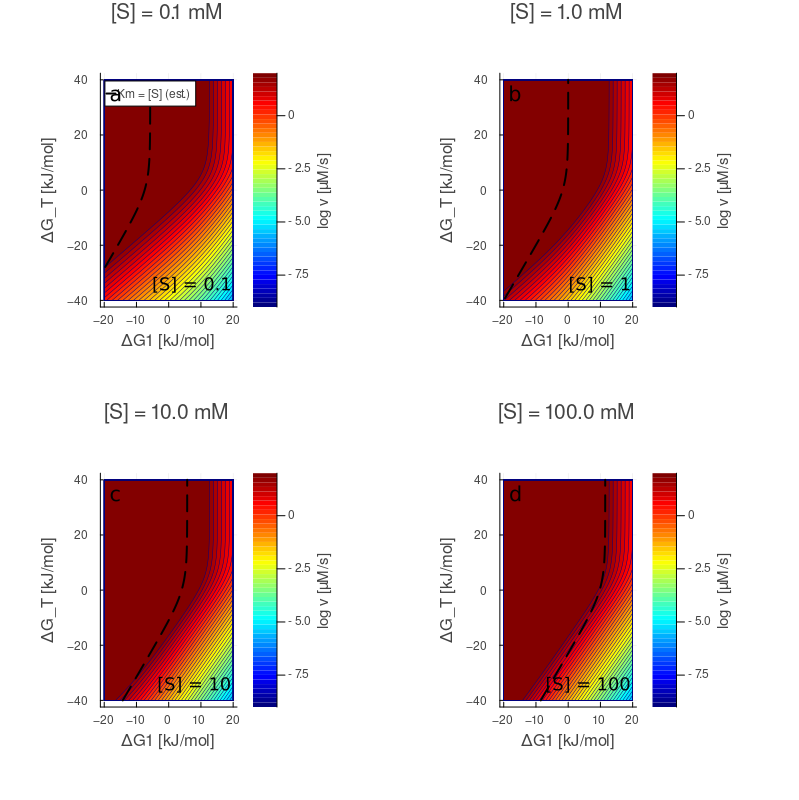

In [18]:
# 顯示四步驟火山圖
volcano_plot_four

### 4.5 結論

1.  **三步驟模型比較**：Python 和 Julia 實現的三步驟模型顯示出非常接近的結果，驗證了實現之間的一致性。
2.  **四步驟模型特性**：Julia 的四步驟模型實現相較於三步驟模型更具靈活性，特別是在考慮產物抑制和多步驟反應時。
3.  **最適 Km 值**：三步驟和四步驟模型在不同底物濃度下預測了不同的最適 Km 值，反映了模型對反應機制假設的敏感性。